# Problem
Infer latent promoter activity from measured nascent-RNA fluorescence. The desired posterior describes promoter ON probability; transition probabilities, fluorescence loading and noise are inferred jointly. There are no experimentally observed hidden-state labels or true kinetic parameters.

In [1]:
from pathlib import Path
import os,sys,time,json,numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not(ROOT/'src').is_dir():ROOT=ROOT.parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.main import reconstruct
from src.solvers import PromoterModel
from src.visualization import *
from evaluation.judge import evaluate
values,lengths,processed=load_data()
with np.load('notebooks/reference_outputs/corrected_original.npz',allow_pickle=False) as z:original={k:z[k].copy() for k in z.files}

## Data
All63 author-selected Drosophila ush traces are used, retaining every valid frame. Fluorescence is an author-processed microscope measurement with arbitrary relative units, not a molecule-count calibration. Lengths distinguish valid zero observations from padding. The corrected original results are an independent method reference, not biological truth.
The original example preprocessing removes the twenty lowest-mean fluorescence traces before selecting region0; this is a filtered regional acquisition, not the entire embryo. All valid frames of the resulting63 traces are retained. This selection preceded both original and local inference.

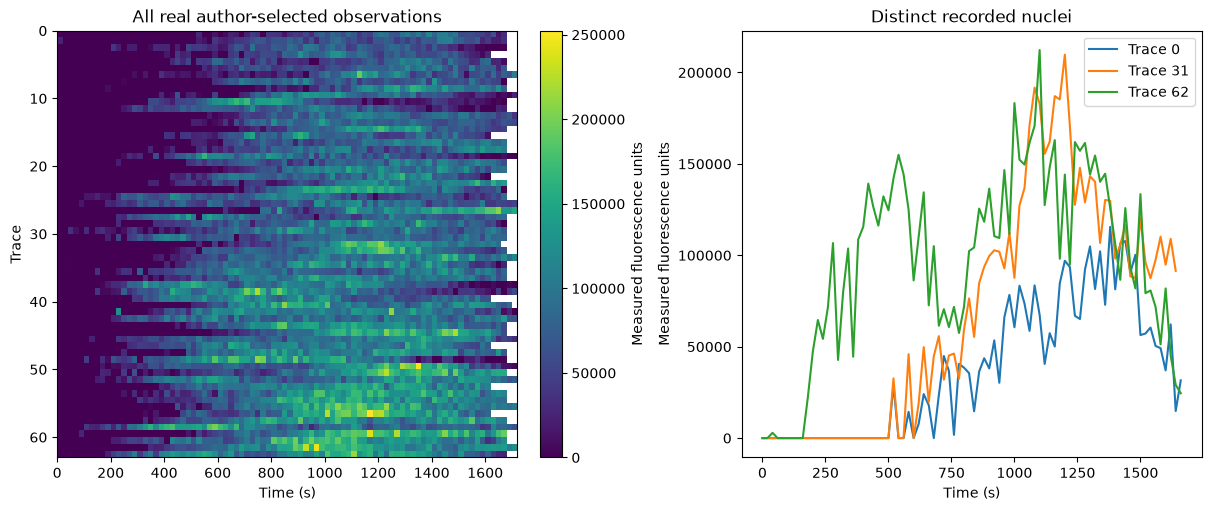

In [2]:
observation_figure(values,lengths);plt.show()

## Physics

The promoter state z(t) is0 for OFF and1 for ON. With loading amplitudes v0,v1, the observation model is

$$y_t=\sum_{j=0}^{18}w_jv_{z_{t-j}}+\epsilon_t,\qquad\epsilon_t\sim N(0,\sigma^2).$$

Weights are(1/3,11/12,1,...,1), most recent first;17 trailing ones complete19frames. The frame interval is20seconds. All unavailable prehistory states are OFF and their full OFF loading contribution remains included. This assumption is crucial when OFF loading is nonzero. Camera processing, biological variability and unmodeled elongation effects remain limitations.

## Method

Retained-beam compound-state forward/backward recursion approximates the19-frame latent history, followed by Gaussian emission normal equations and transition/noise updates. The selected beam is32states; five fixed-transition warmup steps precede up to100 joint EM steps. Relative stopping tolerances are.01 and.001. This is not exact full-state EM.

The distributed original likelihood and M-step disagree on early prehistory. An independent derivative test exposed the mismatch. A separately archived minimal correction removes only the M-step early OFF subtraction, making its basis agree with the actual likelihood. This task uses that explicitly corrected reference branch. Unchanged original failures remain documented; they are not called a successful reproduction.


v_init
[[  813.63600698]
 [14882.94508986]]
A_init
[[0.64934583 0.53004461]
 [0.35065417 0.46995539]]
noise_init
28196.542298680964
EM (fixed) step number: 
0


D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch11_20261027\bio_med\tasks\nascent_transcription_promoter_dynamics\src\solvers.py:735: RuntimeWarning: divide by zero encountered in log
  fluo_logs_abs = np.log(np.abs(data))
D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch11_20261027\bio_med\tasks\nascent_transcription_promoter_dynamics\src\physics_model.py:57: RuntimeWarning: divide by zero encountered in log
  F0_log = np.log(adjust_zeros)


0.3781033567991968
0.0
0.35014790198496415
0.0697487539641541
0
A: 
[[0.64934583 0.53004461]
 [0.35065417 0.46995539]]
pi0: 
[[0.99683583 0.00316417]]
noise: 
18323.582169567522
v: 
[  414.45540503 15939.39837899]
lltot: 
-62978.978151807525
EM (fixed) step number: 
1


0.003169155624775995
0.0
0.08894055694070509
0.027175808280074935
0.2211580362563425
A: 
[[0.64934583 0.53004461]
 [0.35065417 0.46995539]]
pi0: 
[[1. 0.]]
noise: 
16693.872566257414
v: 
[  171.92870473 16377.19580056]
lltot: 
-61805.292453395115
EM (fixed) step number: 
2


1.291411422244964e-12
0.0
0.015561299046010198
0.010535180720903436
0.018763730206889432
A: 
[[0.64934583 0.53004461]
 [0.35065417 0.46995539]]
pi0: 
[[1. 0.]]
noise: 
16434.0942230179
v: 
[   30.08125223 16550.6171222 ]
lltot: 
-61705.71333718715
EM (fixed) step number: 
3


...

59


60


61


62


5.577760475722241e-13
2.0303321357401686e-05
0.00040978729387894635
0.0010296266715808567
0
A: 
[[0.92303467 0.12070138]
 [0.07696533 0.87929862]]
pi0: 
[[1. 0.]]
noise: 
17406.98086629327
v: 
[  131.90195166 10582.86817705]
lltot: 
-60685.64999496573
Complete fresh full reconstruction seconds: 817.1967424999457
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "posterior_rmse": 1.371798225328536e-13,
    "transition_rmse": 7.0004773933027525e-15,
    "initial_rmse": 2.254652770669901e-13,
    "emission_relative_l2": 1.4289285102721107e-14,
    "noise_relative_error": 1.0835776720341528e-13
  },
  "thresholds": {
    "posterior_rmse": {
      "comparison": "<=",
      "boundary": 0.01
    },
    "transition_rmse": {
      "comparison": "<=",
      "boundary": 0.005
    },
    "initial_rmse": {
      "comparison": "<=",
      "boundary": 0.005
    },
    "emission_relative_l2": {
      "comparison": "<=",
      "boundary": 0.01
    },
    "noise_relative_error": {
      "compar

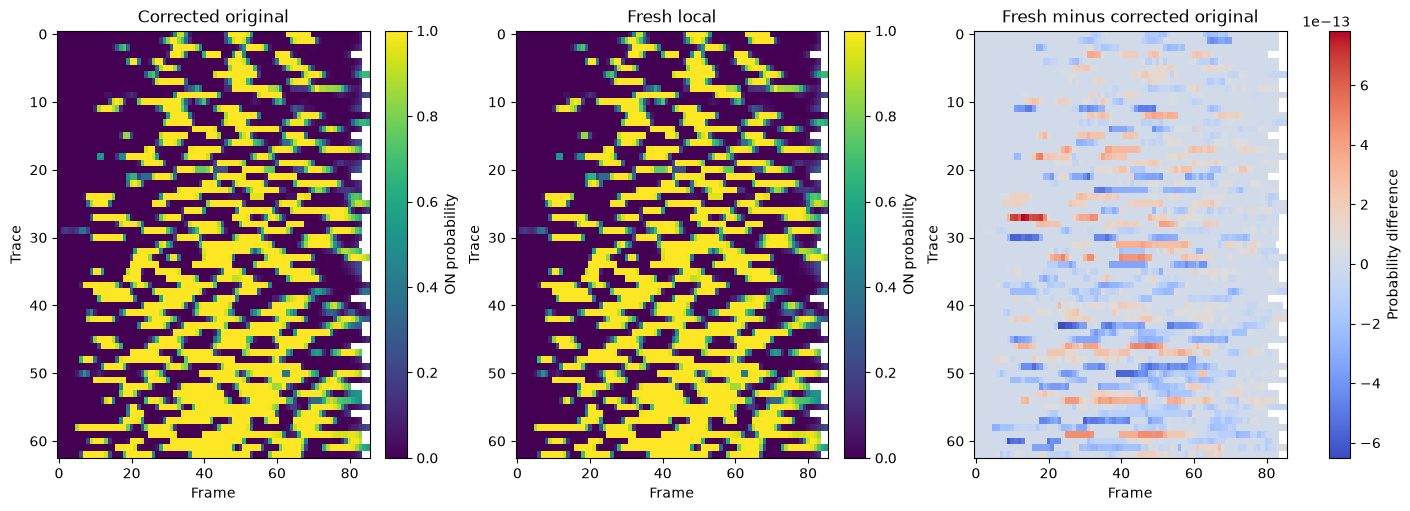

In [3]:
tick=time.perf_counter()
fresh=reconstruct()
seconds=time.perf_counter()-tick
np.savez_compressed('output/reconstruction.npz',**fresh)
report=evaluate('output/reconstruction.npz')
print('Complete fresh full reconstruction seconds:',seconds)
print(json.dumps(report,indent=2));assert report['passed']
posterior_figure(fresh,original,lengths);plt.show()

## Results
Both posterior maps were inferred from the same complete measured acquisition by independently identified implementations. Their agreement tests the extraction and correction, while the remaining residual and entropy characterize conditional model uncertainty. It does not establish actual promoter-state accuracy. Padding is excluded from metrics and displayed as missing rather than a dark OFF region.

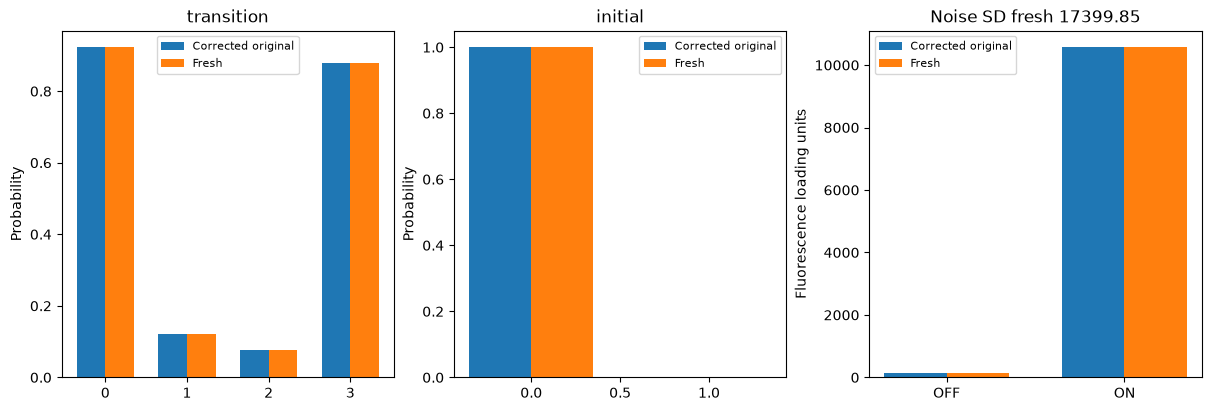

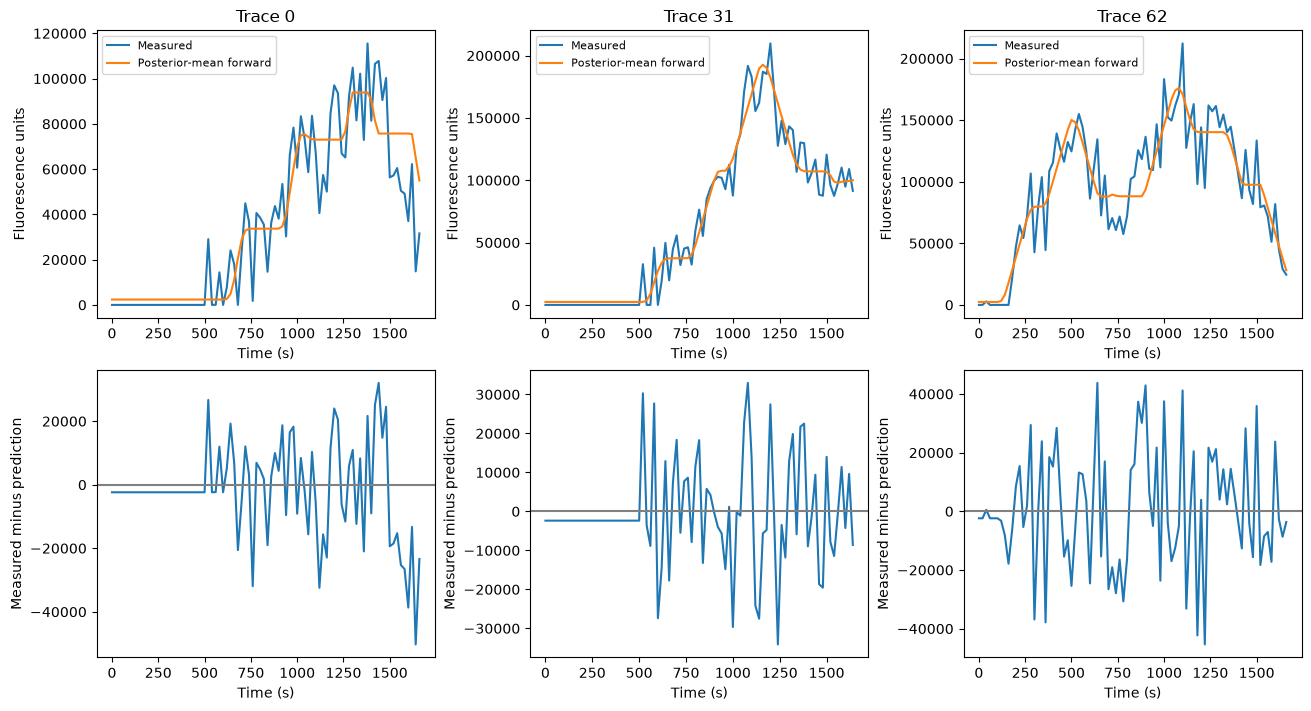

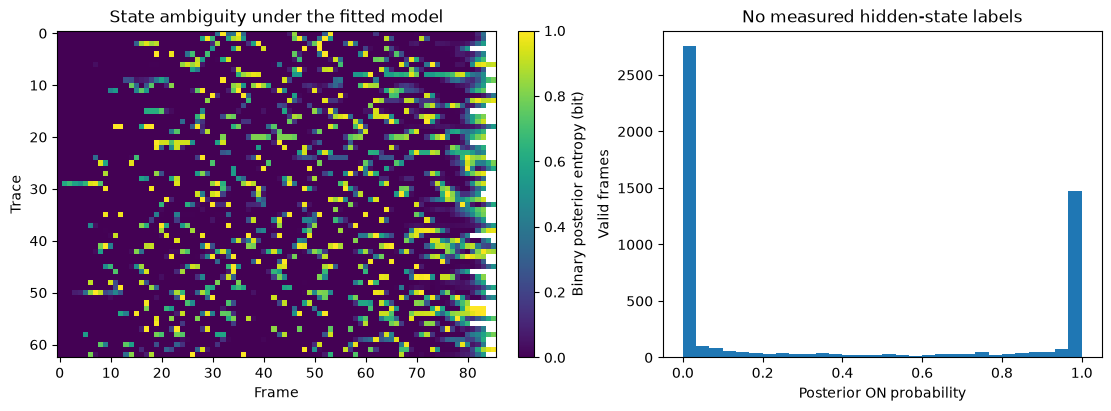

In [4]:
parameter_figure(fresh,original);plt.show()
residual_figure(values,lengths,fresh);plt.show()
entropy_figure(fresh,lengths);plt.show()

### Conditional inference sensitivity
The next experiments retain the freshly inferred global parameters and re-run posterior inference on all63traces at beam sizes16and64 and doubled noise. They test posterior sensitivity, not three newly trained models or independent biological experiments. The standard reconstruction above still uses the complete selected32-state training path.

D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch11_20261027\bio_med\tasks\nascent_transcription_promoter_dynamics\src\solvers.py:1098: RuntimeWarning: divide by zero encountered in log
  pi0_log = np.log(initialised_parameters['pi0'])
D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch11_20261027\bio_med\tasks\nascent_transcription_promoter_dynamics\src\solvers.py:1138: RuntimeWarning: divide by zero encountered in log
  fluo_logs_abs = np.log(np.abs(data))


0
1


2
3


4
5


6
7


...

59


60


61


62


5.169198402659784e-13
0.0005843965816966784
0.4322031772257286
0.01948407037411465
0
A: 
[[0.93708665 0.09791976]
 [0.06291335 0.90208024]]
pi0: 
[[1. 0.]]
noise: 
19759.159807320942
v: 
[  327.76994686 10361.61994957]
lltot: 
-62215.28741429292
Noise times2 seconds 17.690000799950212


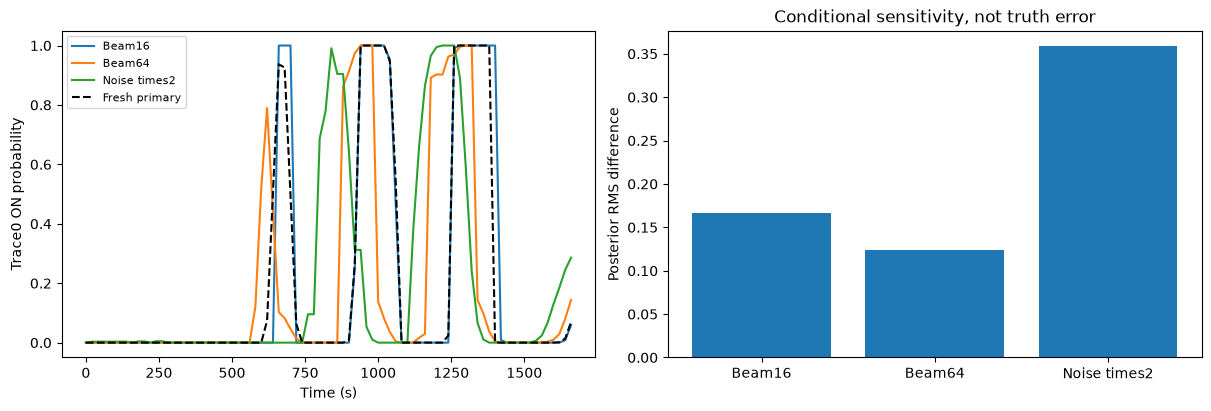

In [5]:
parameters={'A':fresh['transition'][0],'v':fresh['emission'][0].reshape(2,1),'noise':float(fresh['noise'][0,0]),'pi0':fresh['initial'][0].reshape(2,1)}
variants={}
for label,beam,noise in [('Beam16',16,1),('Beam64',64,1),('Noise times2',32,2)]:
    model=PromoterModel(2,19,30,20,1.5,2**19,processed)
    p=dict(parameters);p['noise']*=noise
    tick=time.perf_counter();post=model.get_promoter_traces(p,1,len(lengths),beam,.001,451134116)
    a=np.zeros_like(values)
    for i,L in enumerate(lengths):a[i,:L]=np.exp(post[i])[1]
    variants[label]=a;print(label,'seconds',time.perf_counter()-tick)
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained')
valid=np.arange(86)[None,:]<lengths[:,None]
for label,a in variants.items():
    axs[0].plot(np.arange(lengths[0])*20,a[0,:lengths[0]],label=label)
axs[0].plot(np.arange(lengths[0])*20,fresh['posterior'][0,0,:lengths[0]],'k--',label='Fresh primary')
axs[0].set(xlabel='Time (s)',ylabel='Trace0 ON probability');axs[0].legend(fontsize=8)
axs[1].bar(list(variants),[float(np.sqrt(np.mean((a[valid]-fresh['posterior'][0,valid])**2))) for a in variants.values()]);axs[1].set(ylabel='Posterior RMS difference',title='Conditional sensitivity, not truth error');plt.show()

### Original inconsistency diagnostic
The unchanged original algorithm completed numerically, but its early emission M-step does not match its likelihood. Its parameter estimates below are retained as a diagnostic alongside the independently corrected original and fresh corrected implementation. No uncomputed original posterior is fabricated. The small analytic case compares response weights at state0/frame0.

Unchanged inconsistent original {'A00': 0.9259871032062615, 'A01': 0.1201945834925974, 'A10': 0.07401289679373783, 'A11': 0.8798054165074024, 'vOFF': 313.66550581896706, 'vON': 10533.682225341136, 'noiseSD': 17556.848089664876}
Corrected original {'A00': 0.9230261238762677, 'A01': 0.12052382648175777, 'A10': 0.07697387612373217, 'A11': 0.8794761735182421, 'vOFF': 129.96616049182407, 'vON': 10572.005264333231, 'noiseSD': 17399.850628588396}
Fresh corrected {'A00': 0.9230261238762579, 'A01': 0.12052382648175713, 'A10': 0.07697387612374215, 'A11': 0.8794761735182429, 'vOFF': 129.96616049181853, 'vON': 10572.00526433308, 'noiseSD': 17399.85062859028}


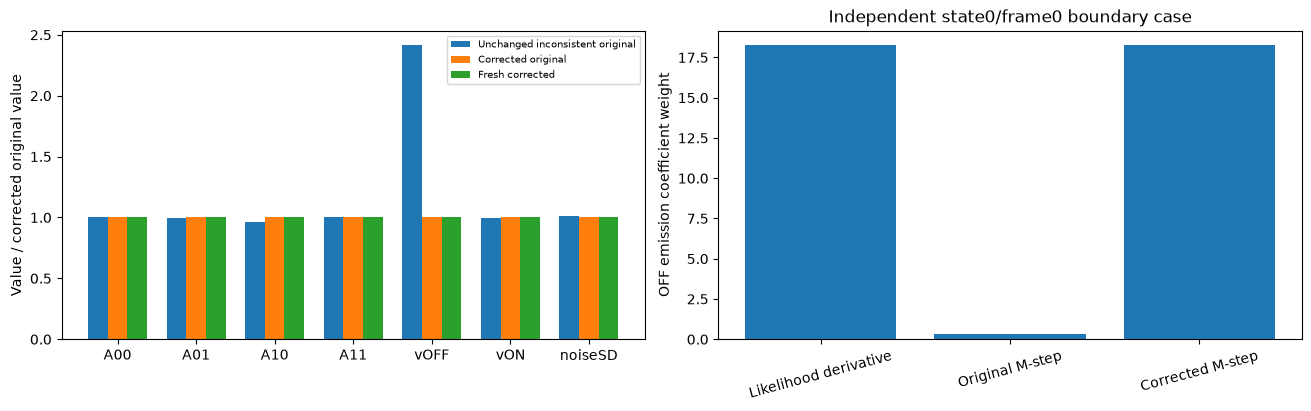

In [6]:
with np.load('notebooks/reference_outputs/uncorrected_original.npz',allow_pickle=False) as z:uncorrected={k:z[k].copy() for k in z.files}
keys=['transition','emission','noise']
base=np.concatenate([original[k].ravel() for k in keys])
fig,axs=plt.subplots(1,2,figsize=(13,4),layout='constrained')
pos=np.arange(7)
for j,(label,r) in enumerate([('Unchanged inconsistent original',uncorrected),('Corrected original',original),('Fresh corrected',fresh)]):
    vals=np.concatenate([r[k].ravel() for k in keys]);axs[0].bar(pos+(j-1)*.25,vals/base,.25,label=label);print(label,dict(zip(['A00','A01','A10','A11','vOFF','vON','noiseSD'],vals.tolist())))
axs[0].set(xticks=pos,xticklabels=['A00','A01','A10','A11','vOFF','vON','noiseSD'],ylabel='Value / corrected original value');axs[0].legend(fontsize=7)
axs[1].bar(['Likelihood derivative','Original M-step','Corrected M-step'],[18.25,1/3,18.25]);axs[1].set(ylabel='OFF emission coefficient weight',title='Independent state0/frame0 boundary case');axs[1].tick_params(axis='x',rotation=15);plt.show()


## Conclusion
The full measured traces support a conditional, temporally resolved estimate of promoter activity and switching. Independent corrected-reference parity validates local numerical extraction; it does not supply true hidden states. Finite beam memory, Gaussian noise, prehistory assumptions and loading ambiguity must remain visible when interpreting the inferred kinetics. The original early-boundary defect is explicitly distinguished from the corrected model, and no measured frames were discarded to conceal it.